Cleaned Laptop Dataset:
  Laptop ID  Brand                    Model     Category  \
0    LP-101  Apple      MacBook Air 13 (M4)    Ultrabook   
1    LP-102  Apple  MacBook Pro 14 (M4 Pro)  Workstation   
2    LP-103  Apple  MacBook Pro 16 (M4 Max)  Workstation   
3    LP-104   Dell            XPS 13 (9350)    Ultrabook   
4    LP-105   Dell            XPS 16 (9640)      Creator   

                 Processor  RAM (GB)  Storage (GB) Storage Type  \
0       Apple M4 (10-Core)      16.0           512          SSD   
1   Apple M4 Pro (12-Core)      24.0          1024          SSD   
2   Apple M4 Max (16-Core)      48.0          2048          SSD   
3  Intel Core Ultra 7 258V      32.0          1024          SSD   
4  Intel Core Ultra 9 185H      32.0          1024          SSD   

                      GPU  Screen Size (in) Resolution  Refresh Rate (Hz)  \
0  Integrated 10-Core GPU              13.6  2560x1664               60.0   
1  Integrated 16-Core GPU              14.2  3024x1964    

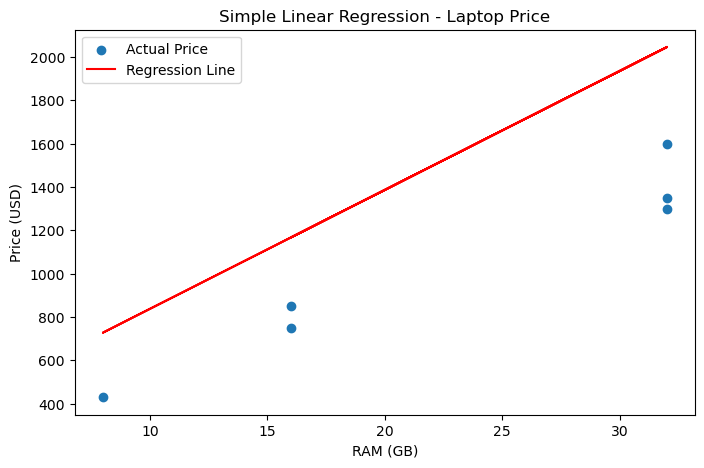


===== MULTIPLE LINEAR REGRESSION =====

Actual Values:
[1349  429 1299  849  749 1599]

Predicted Values:
[1510.85601266  393.92796474 1448.0136315   869.94486263  915.24083737
 1734.54593079]

R2 Score: 0.9008804523744128
Mean Squared Error: 16013.313583067074


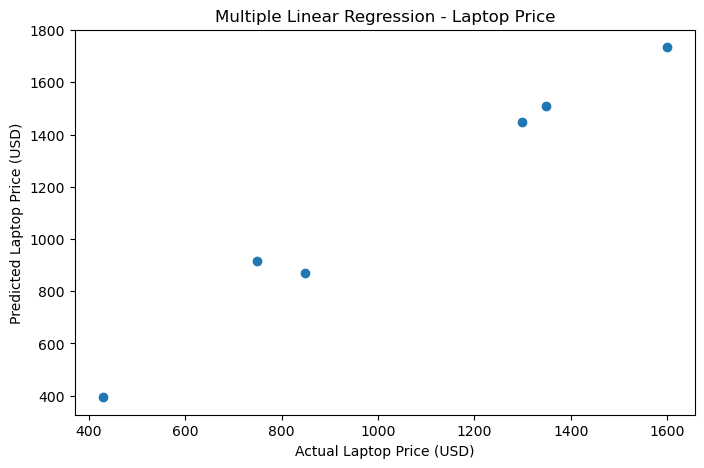


===== LAB COMPLETED SUCCESSFULLY! =====


In [19]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# 1. Load laptop dataset
df = pd.read_csv("laptop.csv", sep="\t")

# 2. Remove extra spaces from column names
df.columns = df.columns.str.strip()

# 3. Keep only actual laptop records
df = df[df['Laptop ID'].astype(str).str.startswith('LP-')].copy()

# 4. Clean numeric columns
numeric_columns = [
    'RAM (GB)',
    'Storage (GB)',
    'Screen Size (in)',
    'Refresh Rate (Hz)',
    'Weight (kg)',
    'Battery Life (hrs)',
    'Price (USD)'
]

for col in numeric_columns:
    df[col] = (
        df[col].astype(str)
        .str.replace(',', '', regex=False)
        .str.replace('$', '', regex=False)
        .str.strip()
    )

    df[col] = pd.to_numeric(df[col], errors='coerce')

# 5. Remove rows with missing numeric values
df = df.dropna(subset=numeric_columns)

print("Cleaned Laptop Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)


# =====================================
# 6. SIMPLE LINEAR REGRESSION
# =====================================

print("\n===== SIMPLE LINEAR REGRESSION =====")

# Input and output
X = df[['RAM (GB)']]
y = df['Price (USD)']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create model
simple_model = LinearRegression()

# Train model
simple_model.fit(X_train, y_train)

# Predict values
y_pred = simple_model.predict(X_test)

# Results
print("\nActual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

print("\nR2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

# Plot graph
plt.figure(figsize=(8, 5))
plt.scatter(X_test['RAM (GB)'], y_test, label="Actual Price")
plt.plot(
    X_test['RAM (GB)'],
    y_pred,
    color='red',
    label="Regression Line"
)

plt.xlabel("RAM (GB)")
plt.ylabel("Price (USD)")
plt.title("Simple Linear Regression - Laptop Price")
plt.legend()
plt.show()


# =====================================
# 7. MULTIPLE LINEAR REGRESSION
# =====================================

print("\n===== MULTIPLE LINEAR REGRESSION =====")

# Multiple input features
X = df[
    [
        'RAM (GB)',
        'Storage (GB)',
        'Screen Size (in)',
        'Refresh Rate (Hz)',
        'Weight (kg)',
        'Battery Life (hrs)'
    ]
]

y = df['Price (USD)']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create model
multiple_model = LinearRegression()

# Train model
multiple_model.fit(X_train, y_train)

# Predict values
y_pred_multiple = multiple_model.predict(X_test)

# Results
print("\nActual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred_multiple)

print("\nR2 Score:", r2_score(y_test, y_pred_multiple))
print("Mean Squared Error:",
      mean_squared_error(y_test, y_pred_multiple))

# Plot graph
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_multiple)

plt.xlabel("Actual Laptop Price (USD)")
plt.ylabel("Predicted Laptop Price (USD)")
plt.title("Multiple Linear Regression - Laptop Price")

plt.show()

print("\n===== LAB COMPLETED SUCCESSFULLY! =====")
